<a href="https://colab.research.google.com/github/aribl233/Network-traffic-anomaly-detection-using-Machine-Learning/blob/main/notebooks/01_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Network Traffic Anomaly Detection

## Exploratory Data Analysis (EDA)

Author: Ariana Blanco

This project aims to explore network traffic data and identify patterns that may help detect anomalous activities and potential cybersecurity threats.

The analysis uses the **CIC-IDS2017 dataset**, which contains network traffic records representing both benign and malicious activities.

### Objectives

- Explore the structure and characteristics of the dataset.
- Analyze the distribution of network traffic records across source files.
- Identify missing values, inconsistencies, and potential data quality issues.
- Examine the distribution of traffic labels and relevant features.
- Gain insights to guide data preprocessing and subsequent machine learning experiments.

### Dataset Overview

The original CSV files are stored in Google Drive and loaded into a single Pandas DataFrame for analysis. A `source_file` column is added to keep track of the origin of each record.

This notebook focuses on understanding the dataset before applying preprocessing techniques and developing machine learning models.


In [6]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define the dataset directory
data_dir = Path("/content/drive/MyDrive/UTDT/CIC-IDS2017")

# Get all CSV files
csv_files = sorted(data_dir.glob("*.csv"))

# Check that CSV files were found
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {data_dir}")

print(f"Found {len(csv_files)} CSV files.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 8 CSV files.


In [7]:
# Load and combine all CSV files
dataset = None

for file in csv_files:
    print(f"Loading: {file.name}")

    df = pd.read_csv(
        file,
        encoding="latin1",
        low_memory=False
    )

    df.columns = df.columns.str.strip()
    df["source_file"] = file.name

    if dataset is None:
        dataset = df
    else:
        dataset = pd.concat([dataset, df], ignore_index=True)

    del df

print("\nDataset loaded successfully!")
print("Dataset shape:", dataset.shape)

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Dataset loaded successfully!
Dataset shape: (3119345, 86)



## Dataset Preview

We inspect the first records to understand how network traffic observations are structured and how the different features are represented.

In [8]:
#Check the dataset
pd.set_option("display.max_columns", None)
dataset.head()

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443.0,192.168.10.5,54865.0,6.0,7/7/2017 3:30,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3.0,3.0,3.0,3.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0,0.0,666666.666700,0.000000,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,9.0,6.0,0.0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,12.0,0.0,0.0,33.0,-1.0,1.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80.0,192.168.10.5,55054.0,6.0,7/7/2017 3:30,109.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,6.0,6.0,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109.0,109.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,20.0,9174.311927,9174.311927,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,9.0,6.0,6.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,6.0,29.0,256.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80.0,192.168.10.5,55055.0,6.0,7/7/2017 3:30,52.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,6.0,6.0,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52.0,52.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,20.0,19230.769230,19230.769230,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,9.0,6.0,6.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,6.0,29.0,256.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443.0,192.168.10.16,46236.0,6.0,7/7/2017 3:30,34.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,6.0,6.0,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34.0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,20.0,29411.764710,29411.764710,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,9.0,6.0,6.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,6.0,31.0,329.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443.0,192.168.10.5,54863.0,6.0,7/7/2017 3:30,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3.0,3.0,3.0,3.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0,0.0,666666.666700,0.000000,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,9.0,6.0,0.0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,12.0,0.0,0.0,32.0,-1.0,1.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv



## Data Types and Structure

This section examines the data types of each feature and provides an overview of the dataset structure. Identifying incorrect data types is an important step before preprocessing.


In [9]:

# Display column information and data types
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3119345 entries, 0 to 3119344
Data columns (total 86 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Flow ID                      object 
 1   Source IP                    object 
 2   Source Port                  float64
 3   Destination IP               object 
 4   Destination Port             float64
 5   Protocol                     float64
 6   Timestamp                    object 
 7   Flow Duration                float64
 8   Total Fwd Packets            float64
 9   Total Backward Packets       float64
 10  Total Length of Fwd Packets  float64
 11  Total Length of Bwd Packets  float64
 12  Fwd Packet Length Max        float64
 13  Fwd Packet Length Min        float64
 14  Fwd Packet Length Mean       float64
 15  Fwd Packet Length Std        float64
 16  Bwd Packet Length Max        float64
 17  Bwd Packet Length Min        float64
 18  Bwd Packet Length Mean       float64
 19  

In [10]:

# Count columns by data type
dataset.dtypes.value_counts()


,count
float64,80
object,6



## Missing Values Analysis

We investigate missing values across the dataset to identify incomplete features and assess potential data quality issues.


In [11]:

# Calculate missing values and percentages
missing_values = pd.DataFrame({
    "Missing Values": dataset.isnull().sum(),
    "Percentage": (dataset.isnull().mean() * 100)
})

# Keep only columns with missing values
missing_values = missing_values[
    missing_values["Missing Values"] > 0
].sort_values(by="Percentage", ascending=False)

missing_values


,Missing Values,Percentage
Flow Bytes/s,289960,9.295541
Source IP,288602,9.252006
Source Port,288602,9.252006
Destination IP,288602,9.252006
Flow ID,288602,9.252006
...,...,...
Idle Mean,288602,9.252006
Idle Std,288602,9.252006
Idle Max,288602,9.252006
Idle Min,288602,9.252006



## Duplicate Records

We check for duplicate observations to identify potentially repeated records that could affect the analysis and model evaluation.


In [12]:

# Check for exact duplicate records
# Exclude source_file to detect identical traffic records
duplicates = dataset.drop(columns=["source_file"]).duplicated().sum()

print(f"Number of duplicate records: {duplicates:,}")
print(f"Percentage of duplicates: {duplicates / len(dataset) * 100:.2f}%")


Number of duplicate records: 288,804
Percentage of duplicates: 9.26%



## 6. Target Variable Distribution

We analyze the distribution of the target variable to understand the proportion of benign and malicious network traffic.

Class distribution is particularly important in cybersecurity datasets, as imbalanced classes can affect machine learning performance.


In [13]:

# Identify the target variable
label_col = next(
    (col for col in dataset.columns if col.lower() == "label"),
    None
)

if label_col is None:
    raise ValueError("Target column 'Label' was not found.")

# Count records per class
label_counts = dataset[label_col].astype("string").str.strip().value_counts()

# Calculate percentages
label_percentages = label_counts / len(dataset) * 100

# Create summary table
label_distribution = pd.DataFrame({
    "Records": label_counts,
    "Percentage": label_percentages
})

label_distribution


,Records,Percentage
Label,,
BENIGN,2273097,72.870971
DoS Hulk,231073,7.407741
PortScan,158930,5.09498
DDoS,128027,4.104291
DoS GoldenEye,10293,0.329973
FTP-Patator,7938,0.254477
SSH-Patator,5897,0.189046
DoS slowloris,5796,0.185808
DoS Slowhttptest,5499,0.176287


/tmp/ipykernel_454/2323325299.py:19: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


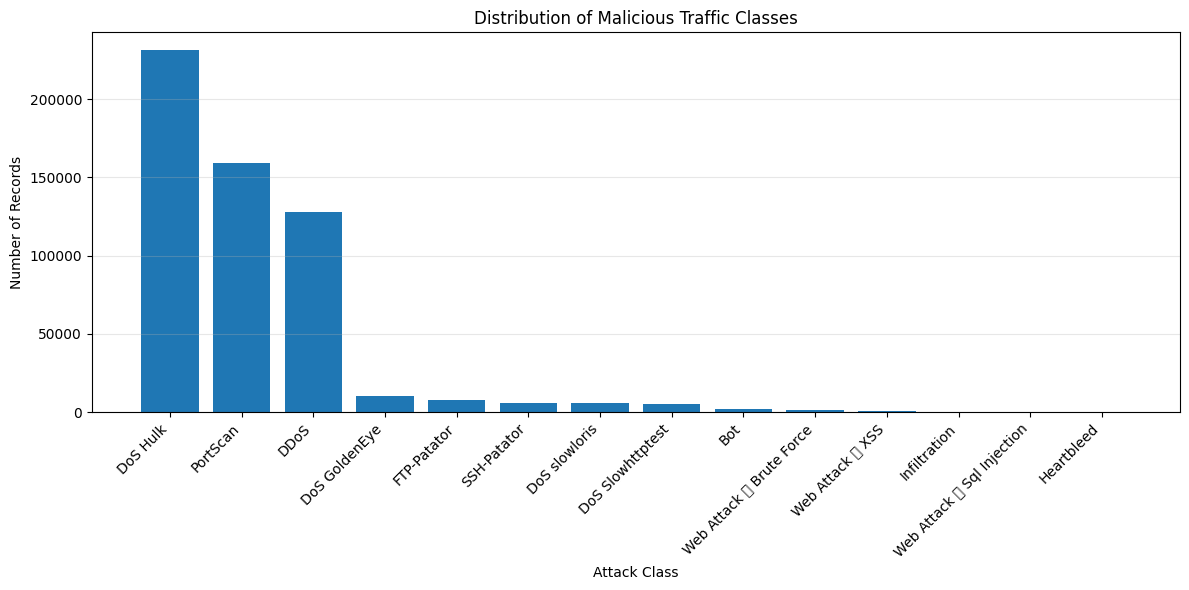

In [16]:
# Exclude BENIGN class
attack_counts = label_counts[
    label_counts.index.str.strip().str.upper() != "BENIGN"
]

plt.figure(figsize=(12, 6))

bars = plt.bar(
    attack_counts.index,
    attack_counts.values
)

plt.title("Distribution of Malicious Traffic Classes")
plt.xlabel("Attack Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Traffic Classes by Source File

We examine how traffic classes are distributed across the original CSV files. This helps identify whether certain attack types are associated with specific capture periods or source files.


In [17]:

# Cross-tabulation of source files and traffic classes
source_label_counts = pd.crosstab(
    dataset["source_file"],
    dataset[label_col]
)

source_label_counts


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack  Brute Force,Web Attack  Sql Injection,Web Attack  XSS
source_file,,,,,,,,,,,,,,,
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,97718,0,128027,0,0,0,0,0,0,0,0,0,0,0,0
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,127537,0,0,0,0,0,0,0,0,0,158930,0,0,0,0
Friday-WorkingHours-Morning.pcap_ISCX.csv,189067,1966,0,0,0,0,0,0,0,0,0,0,0,0,0
Monday-WorkingHours.pcap_ISCX.csv,529918,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288566,0,0,0,0,0,0,0,0,36,0,0,0,0,0
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,168186,0,0,0,0,0,0,0,0,0,0,0,1507,21,652
Tuesday-WorkingHours.pcap_ISCX.csv,432074,0,0,0,0,0,0,7938,0,0,0,5897,0,0,0
Wednesday-workingHours.pcap_ISCX.csv,440031,0,0,10293,231073,5499,5796,0,11,0,0,0,0,0,0


/tmp/ipykernel_454/1458900739.py:12: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


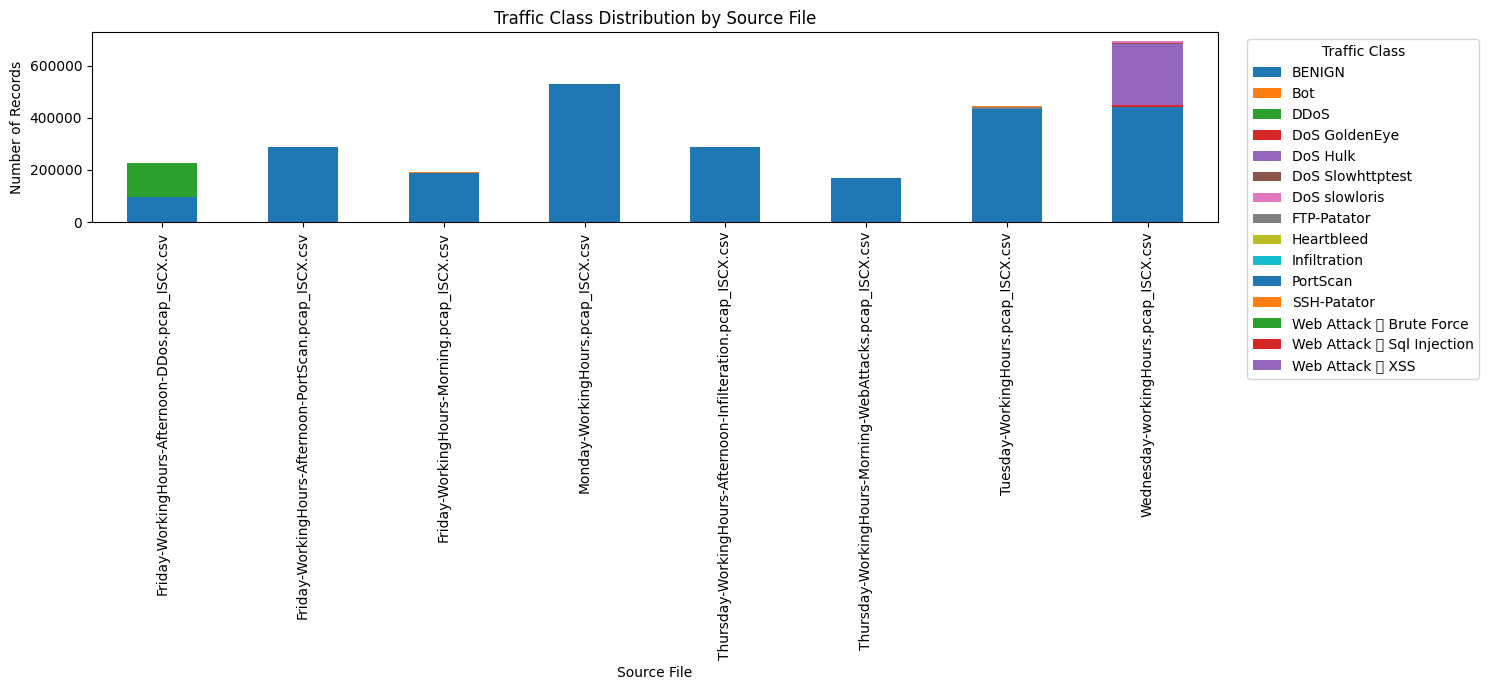

In [18]:


source_label_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

plt.title("Traffic Class Distribution by Source File")
plt.xlabel("Source File")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.legend(title="Traffic Class", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()



## 8. Statistical Summary

We calculate descriptive statistics for numerical features to understand their distributions, variability, and potential anomalies.


In [19]:

# Select numerical columns
numeric_columns = dataset.select_dtypes(include=np.number).columns

# Generate descriptive statistics
dataset[numeric_columns].describe().T


,count,mean,std,min,25%,50%,75%,max
Source Port,2830743.0,4.112886e+04,2.229494e+04,0.0,32774.0,50944.0,58413.0,65535.0
Destination Port,2830743.0,8.071483e+03,1.828363e+04,0.0,53.0,80.0,443.0,65535.0
Protocol,2830743.0,9.880341e+00,5.261922e+00,0.0,6.0,6.0,17.0,17.0
Flow Duration,2830743.0,1.478566e+07,3.365374e+07,-13.0,155.0,31316.0,3204828.5,119999998.0
Total Fwd Packets,2830743.0,9.361160e+00,7.496728e+02,1.0,2.0,2.0,5.0,219759.0
...,...,...,...,...,...,...,...,...
Active Min,2830743.0,5.829582e+04,5.770923e+05,0.0,0.0,0.0,0.0,110000000.0
Idle Mean,2830743.0,8.316037e+06,2.363008e+07,0.0,0.0,0.0,0.0,120000000.0
Idle Std,2830743.0,5.038439e+05,4.602984e+06,0.0,0.0,0.0,0.0,76900000.0
Idle Max,2830743.0,8.695752e+06,2.436689e+07,0.0,0.0,0.0,0.0,120000000.0



## Numerical Feature Distributions

We visualize selected numerical features to understand their distributions and identify potential skewness, unusual values, and patterns that may be relevant for anomaly detection.


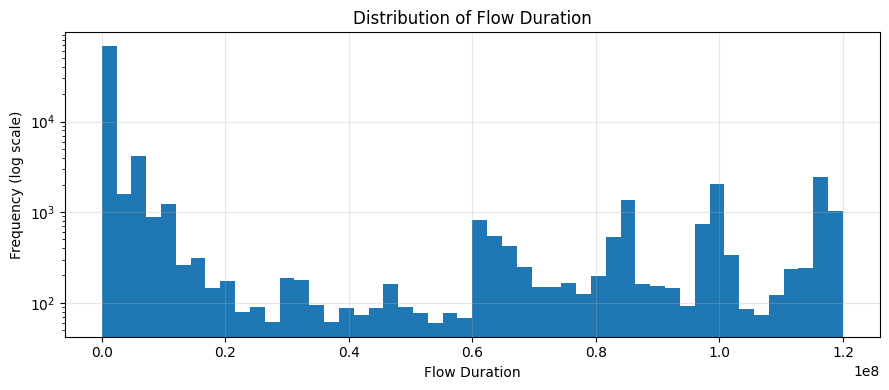

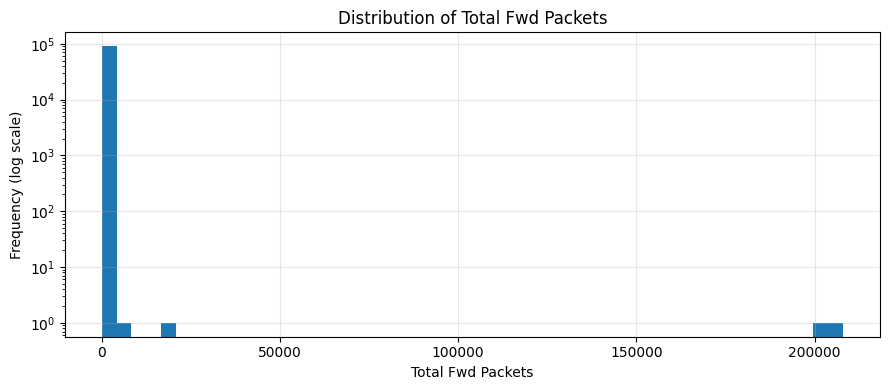

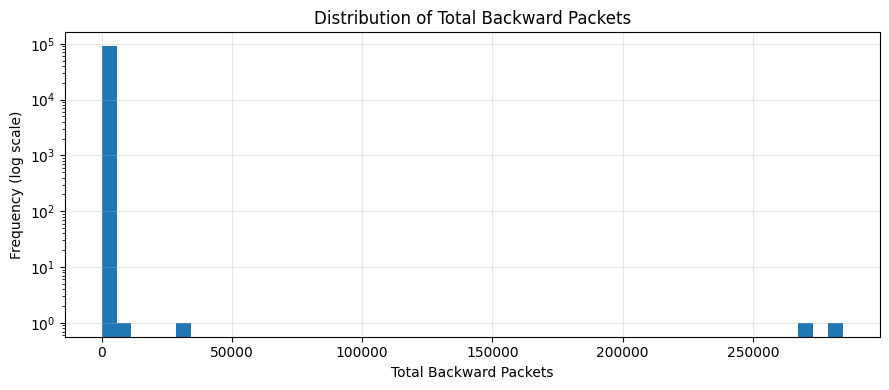

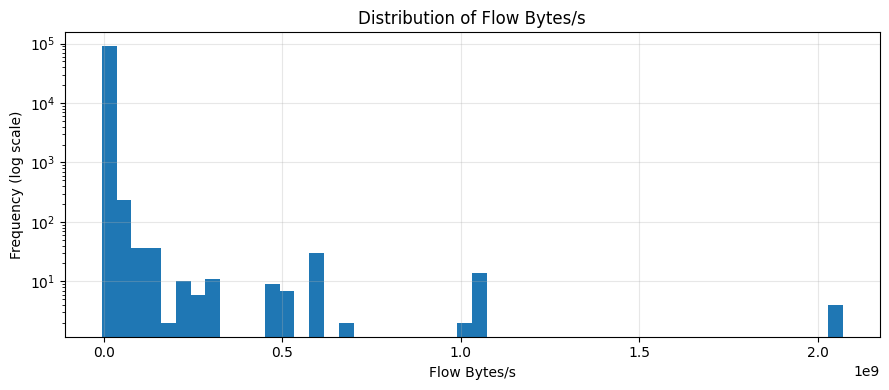

In [20]:

# Select relevant features available in the dataset
selected_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s"
]

selected_features = [
    col for col in selected_features
    if col in numeric_columns
]

# Use a sample to make visualization more efficient
sample_size = min(100_000, len(dataset))
sample = dataset.sample(n=sample_size, random_state=42)

for feature in selected_features:
    values = pd.to_numeric(sample[feature], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    plt.figure(figsize=(9, 4))
    plt.hist(values, bins=50, log=True)

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency (log scale)")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()



## Correlation Analysis

We explore correlations between numerical features to identify relationships and potential redundancy among variables.

This analysis can help guide feature selection during the preprocessing stage.


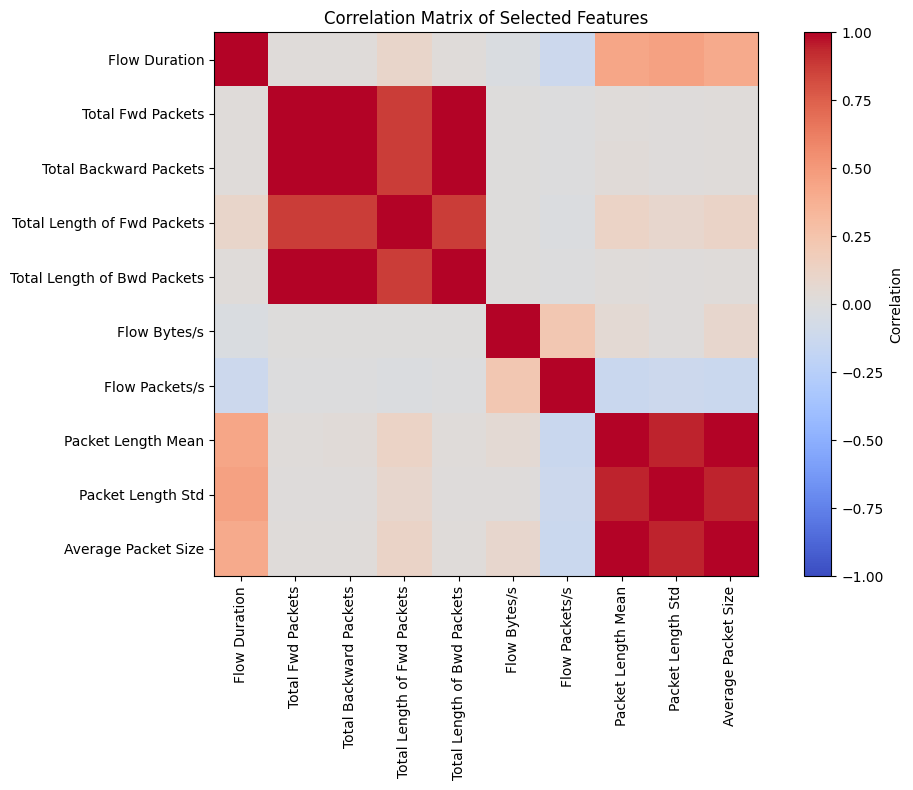

In [21]:

# Select a subset of numerical features
correlation_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Packet Length Std",
    "Average Packet Size"
]

correlation_features = [
    col for col in correlation_features
    if col in numeric_columns
]

# Calculate correlation matrix using a sample
correlation_sample = dataset.sample(
    n=min(100_000, len(dataset)),
    random_state=42
)

correlation_matrix = correlation_sample[
    correlation_features
].replace([np.inf, -np.inf], np.nan).corr()

# Visualize correlation matrix
plt.figure(figsize=(11, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=90
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features
)

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()


## 11. Exploratory Data Analysis Conclusions

The exploratory analysis provides an initial understanding of the CIC-IDS2017 dataset.

Key observations:

- **Dataset structure:** The 8 CSV files (one per capture session, Monday to Friday) were combined into a single DataFrame of 3,119,345 records and 86 columns (80 numerical, 6 of type `object`). Each attack type appears in only one source file, and Monday contains exclusively benign traffic.
- **Data quality:** 288,602 rows (9.25%) are completely empty and must be removed, leaving 2,830,743 valid records. Almost all detected duplicates (288,804) come from these empty rows. `Flow Bytes/s` has 1,358 additional missing values and may contain infinite values. `Flow Duration` includes negative values (minimum of -13), which are invalid. The `Label` column also has an encoding issue (`\x96` character in the Web Attack classes).
- **Class distribution:** Considering only valid records, benign traffic represents 80.3% and malicious traffic 19.7%. The attacks are dominated by DoS Hulk, PortScan and DDoS, while classes such as Web Attack (SQL Injection), Infiltration and Heartbleed have fewer than 40 records, showing an extreme class imbalance.
- **Feature distributions:** Numerical features are highly skewed with heavy tails. For example, `Total Fwd Packets` has a median of 2 but a maximum of 219,759, and `Flow Bytes/s` reaches values close to 2×10⁹. `Flow Duration` shows a multimodal distribution with a second group of long flows near the 120-second limit.
- **Feature relationships:** Strong correlations appear among packet count and length features (`Total Fwd Packets`, `Total Backward Packets`, `Total Length of Bwd Packets`) and among `Packet Length Mean`, `Packet Length Std` and `Average Packet Size`, indicating redundancy. This analysis covers only a subset of 10 features.

### Next Steps

Based on these findings, the preprocessing stage will focus on:

- Removing empty rows, then recomputing duplicates and class percentages.
- Fixing the label encoding and handling invalid values (negative durations, infinite and missing values in `Flow Bytes/s` and `Flow Packets/s`).
- Dropping identifier and leakage-prone columns (`Flow ID`, IP addresses, `Timestamp`, `source_file`).
- Reducing redundant features and applying a transformation or robust scaling to skewed variables.
- Addressing class imbalance and designing a train/test split that avoids learning the capture day instead of the attack behavior.